# The complete audit workflow

An end-to-end subgroup deployment-readiness audit on the public **SUPPORT2**
cohort, section by section: cohort characterisation, discrimination,
calibration, clinical utility, estimability, the recalibration ladder,
intersectional cells, and the secondary effect-size and interaction screens.

It is the long form of `01_audit_report_support2.ipynb` — where that notebook
runs the three axes and hands you a report, this one works through every
analysis the package supports and writes each table and figure as it goes.

Section headings name the corresponding element of the companion paper, so you
can go from a published table to the code that produces it.

## What it produces

CSV and Markdown tables into `results/tables/`, figures into
`results/figures/`. Runtime is roughly 25 minutes at the default B = 2000;
set `ISITFAIR_FAST=1` for a ~3 minute pass while you are editing.

In [1]:
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd

for _c in (Path.cwd(), *Path.cwd().parents):
    if (_c / "examples" / "support2_data.py").exists():
        sys.path.insert(0, str(_c / "examples"))
        break

import isitfair
from isitfair import (
    DEFAULT_EVENT_FLOORS,
    FairnessAudit,
    GroupRecalibration,
    WassersteinPostprocessing,
    bootstrap_metric_difference,
    cohens_d,
    cohens_h,
    compare_periods,
    decision_curve_plot,
    fdr_correct,
    forest_plot,
    interaction_test,
    odds_ratio_2x2,
    recalibration_ladder_plot,
    reliability_plot,
    roc_plot,
    subgroup_forest_plot,
    table_one,
    volcano_plot,
)
from support2_data import SEED, THRESHOLD, fit_reference_model, n_bootstrap, results_dir

# isitfair selects a head-less backend for report rendering unless an inline one
# is already active, so this belongs after the import to be certain it sticks.
import matplotlib
matplotlib.use("module://matplotlib_inline.backend_inline")
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore", category=RuntimeWarning)
plt.rcParams.update({"figure.dpi": 110, "savefig.bbox": "tight", "font.size": 9})

B = n_bootstrap()
TABLES = results_dir("tables")
FIGURES = results_dir("figures")

print(f"isitfair {isitfair.__version__} · seed {SEED} · threshold {THRESHOLD} · B = {B}")


def emit(frame: pd.DataFrame, name: str, caption: str) -> pd.DataFrame:
    """Write a table as both CSV and Markdown, and return it unchanged."""
    frame.to_csv(TABLES / f"{name}.csv", index=False)
    (TABLES / f"{name}.md").write_text(
        f"**{caption}**\n\n" + frame.to_markdown(index=False) + "\n", encoding="utf-8"
    )
    print(f"  wrote {name}.csv / .md  ({len(frame)} rows)")
    return frame


def save(fig, name: str) -> None:
    """Save a figure as both PNG and PDF into results/figures/."""
    # No timestamp or software tag in the files, so a re-run reproduces them byte for byte.
    fig.savefig(FIGURES / f"{name}.png", dpi=150, metadata={"Software": None})
    fig.savefig(FIGURES / f"{name}.pdf", dpi=150, metadata={"CreationDate": None})
    print(f"  wrote {name}.png / .pdf")

isitfair 0.4.0 · seed 99 · threshold 0.3 · B = 2000


## 1. Cohort, model and outcome

*Paper section: Methods — "Cohort, model, and outcome".*

The audited object is a logistic regression for in-hospital mortality, fitted
on a 60% training partition and audited on a held-out 20% test partition. A
further 20% is held back for calibration, so every recalibration in §9 is
fitted on data the audit never sees.

Sex and race are **not** model inputs. They are audit axes.

In [2]:
cohort = fit_reference_model(seed=SEED)
y, p = cohort.y_test, cohort.p_test
attrs = cohort.attrs_test
frame = cohort.frame_test

print(f"training partition   n = {cohort.n_train}")
print(f"calibration partition n = {len(cohort.y_calib)}  events = {int(cohort.y_calib.sum())}")
print(f"AUDITED test partition n = {len(y)}  events = {int(y.sum())}  prevalence = {y.mean():.4f}")

training partition   n = 5463
calibration partition n = 1821  events = 472
AUDITED test partition n = 1821  events = 472  prevalence = 0.2592


## 2. Table 1 — cohort characterisation

*Paper element: **Table 1**, plus the Supplementary Methods' FDR family (c),
"the sex-stratified Table 1 scan".*

`table_one` wraps `tableone` and adds two columns the clinical-fairness
setting needs: a Benjamini–Hochberg q-value across the variables scanned, and
a per-variable effect size with Cohen's qualitative label. The q-value is what
stops a 20-row Table 1 from producing a "significant" difference by counting.

In [3]:
T1_CONTINUOUS = ("age", "num.co", "meanbp", "hrt", "resp", "temp", "crea", "sod", "sps", "aps", "scoma")
T1_BINARY = ("diabetes", "dementia")
T1_CATEGORICAL = ("dzclass", "ca", "race_ethnicity")

t1_sex = table_one(
    frame,
    group_col="sex",
    continuous_cols=T1_CONTINUOUS,
    binary_cols=T1_BINARY,
    categorical_cols=T1_CATEGORICAL,
)
emit(t1_sex.effect_sizes, "table1_by_sex_effect_sizes", "Table 1 (by sex) — effect sizes and BH-FDR")
t1_sex.effect_sizes

  wrote table1_by_sex_effect_sizes.csv / .md  (48 rows)


,variable,kind,p_value,q_fdr,effect_size,effect_kind,magnitude,n
0,age,continuous,0.143,0.361263,0.063179,d,negligible,1821
1,num.co,continuous,0.094,0.300800,-0.079316,d,negligible,1821
2,meanbp,continuous,0.496,0.762000,0.049108,d,negligible,1821
3,hrt,continuous,0.508,0.762000,0.008651,d,negligible,1821
4,resp,continuous,0.505,0.762000,0.034027,d,negligible,1821
5,temp,continuous,0.637,0.800400,0.019646,d,negligible,1821
6,crea,continuous,0.001,0.016000,-0.100106,d,negligible,1807
7,sod,continuous,0.894,0.936511,-0.008899,d,negligible,1821
8,sps,continuous,0.197,0.429818,0.039501,d,negligible,1821
9,aps,continuous,0.246,0.513391,0.042012,d,negligible,1821


The same scan by race/ethnicity. With five levels the effect size switches
from Cohen's d/h to η² and Cramér's V automatically — a two-group effect size
is undefined for k > 2 and is not silently reused.

In [4]:
t1_race = table_one(
    frame,
    group_col="race_ethnicity",
    continuous_cols=T1_CONTINUOUS,
    binary_cols=T1_BINARY,
    categorical_cols=("dzclass", "ca"),
)
emit(
    t1_race.effect_sizes,
    "table1_by_race_effect_sizes",
    "Table 1 (by race/ethnicity) — effect sizes and BH-FDR",
)
t1_race.effect_sizes

  wrote table1_by_race_effect_sizes.csv / .md  (48 rows)


,variable,kind,p_value,q_fdr,effect_size,effect_kind,magnitude,n
0,age,continuous,0.001,0.005333,0.043343,eta2,small,1821
1,num.co,continuous,0.157,0.326000,0.003743,eta2,negligible,1821
2,meanbp,continuous,0.184,0.353280,0.002539,eta2,negligible,1821
3,hrt,continuous,0.261,0.447429,0.002053,eta2,negligible,1821
4,resp,continuous,0.464,0.601946,0.001432,eta2,negligible,1821
5,temp,continuous,0.141,0.307636,0.004680,eta2,negligible,1821
6,crea,continuous,0.641,0.683733,0.002987,eta2,negligible,1807
7,sod,continuous,0.443,0.590667,0.001906,eta2,negligible,1821
8,sps,continuous,0.616,0.683733,0.001559,eta2,negligible,1821
9,aps,continuous,0.260,0.447429,0.002762,eta2,negligible,1821


## 3. Subgroup distribution

*Paper section: Results — "Cohort and subgroup distribution".*

Before any metric: how many patients and how many **events** each subgroup
has. Events, not patients, are what every interval below is built from, so
this table is where the estimability verdicts in §8 come from.

In [5]:
rows = []
for axis, labels in attrs.items():
    for level in np.unique(labels):
        mask = labels == level
        rows.append(
            {
                "attribute": axis,
                "subgroup": level,
                "n": int(mask.sum()),
                "n_events": int(y[mask].sum()),
                "prevalence": round(float(y[mask].mean()), 4),
                "share_of_cohort": round(float(mask.mean()), 4),
            }
        )
emit(pd.DataFrame(rows), "table_subgroup_distribution", "Subgroup distribution in the audited partition")

  wrote table_subgroup_distribution.csv / .md  (11 rows)


,attribute,subgroup,n,n_events,prevalence,share_of_cohort
0,sex,female,787,199,0.2529,0.4322
1,sex,male,1034,273,0.2640,0.5678
2,age_group,18-44,257,65,0.2529,0.1411
3,age_group,45-64,684,171,0.2500,0.3756
4,age_group,65-79,677,172,0.2541,0.3718
5,age_group,80+,203,64,0.3153,0.1115
6,race_ethnicity,asian,13,5,0.3846,0.0071
7,race_ethnicity,black,266,82,0.3083,0.1461
8,race_ethnicity,hispanic,57,10,0.1754,0.0313
9,race_ethnicity,other,32,9,0.2812,0.0176


## 4. The audit object

One construction, three axes, one shared set of bootstrap replicates. Because
every axis draws on the same replicate index array, a gap statistic is a
*reduction over* the stored per-subgroup distributions rather than a second,
independent resample of the data — which is what makes the gap interval
consistent with the subgroup intervals printed beside it.

In [6]:
audit = FairnessAudit(
    y_true=y,
    y_proba=p,
    sensitive_features=attrs,
    threshold=THRESHOLD,
    n_bootstrap=B,
    random_state=SEED,
    resample_scheme="patient",
)
print(audit)

FairnessAudit(n=1821, events=472, threshold=0.3, n_bootstrap=2000, random_state=99, attributes: sex (2), age_group (4), race_ethnicity (5))


## 5. Discrimination

*Paper elements: **Table 2** and **Figure 1**.*

Within-group AUROC/AUPRC and the rates at t = 0.30, then the four parity gaps.
Both halves, always: a gap on its own is equally consistent with one group
being served worse and with both being served badly, and the within-group rows
are what tell them apart.

In [7]:
disc = audit.discrimination()
disc_cols = ["attribute", "subgroup", "n", "n_events", "prevalence",
             "auroc", "auroc_ci_low", "auroc_ci_high", "auprc",
             "sensitivity", "specificity", "ppv", "npv", "not_estimable_final"]
disc_within = disc[disc.subgroup != "GAP"][[c for c in disc_cols if c in disc.columns]].round(4)
emit(disc_within, "table2_discrimination", "Table 2 — within-subgroup discrimination at t = 0.30")
disc_within

  wrote table2_discrimination.csv / .md  (14 rows)


,attribute,subgroup,n,n_events,prevalence,auroc,auroc_ci_low,auroc_ci_high,auprc,sensitivity,specificity,ppv,npv,not_estimable_final
0,sex,Overall,1821.0,472.0,0.2592,0.8460,0.8253,0.8659,0.6943,0.6992,0.8288,0.5882,0.8873,False
1,sex,female,787.0,199.0,0.2529,0.8332,0.8005,0.8640,0.6805,0.7236,0.8112,0.5647,0.8966,False
2,sex,male,1034.0,273.0,0.2640,0.8561,0.8289,0.8805,0.7061,0.6813,0.8423,0.6078,0.8805,False
7,age_group,Overall,1821.0,472.0,0.2592,0.8460,0.8253,0.8659,0.6943,0.6992,0.8288,0.5882,0.8873,False
8,age_group,18-44,257.0,65.0,0.2529,0.8787,0.8288,0.9215,0.7597,0.7385,0.8333,0.6000,0.9040,False
9,age_group,45-64,684.0,171.0,0.2500,0.8602,0.8260,0.8921,0.7205,0.6725,0.8791,0.6497,0.8895,False
10,age_group,65-79,677.0,172.0,0.2541,0.8293,0.7947,0.8602,0.6495,0.6919,0.7980,0.5385,0.8838,False
11,age_group,80+,203.0,64.0,0.3153,0.8115,0.7412,0.8728,0.6855,0.7500,0.7482,0.5783,0.8667,False
16,race_ethnicity,Overall,1821.0,472.0,0.2592,0.8460,0.8253,0.8659,0.6943,0.6992,0.8288,0.5882,0.8873,False
17,race_ethnicity,asian,13.0,5.0,0.3846,0.8000,NaN,NaN,0.6295,0.6000,0.7500,0.6000,0.7500,True


### The four parity gaps

Δ_EOpp (sensitivity), Δ_PE (false-positive rate), Δ_SP (flag rate) and Δ_EO
(the max of the first two). Every one is a property of the decision rule at
**one** threshold; move the threshold and they all move.

In [8]:
gap_cols = ["attribute", "gap_metric", "gap_value", "gap_ci_low", "gap_ci_high", "gap_effect_size", "not_estimable_final"]
gaps = disc[disc.subgroup == "GAP"][[c for c in gap_cols if c in disc.columns]].round(4)
emit(gaps, "table2_discrimination_gaps", "Table 2 — discrimination gap statistics")
gaps

  wrote table2_discrimination_gaps.csv / .md  (12 rows)


,attribute,gap_metric,gap_value,gap_ci_low,gap_ci_high,not_estimable_final
3,sex,equal_opportunity_difference,0.0423,0.0022,0.1263,False
4,sex,predictive_equality,0.0311,0.0021,0.0728,False
5,sex,equalized_odds_gap,0.0423,0.0131,0.1263,False
6,sex,statistical_parity,0.0281,0.0017,0.0714,False
12,age_group,equal_opportunity_difference,0.0775,0.0397,0.2157,False
13,age_group,predictive_equality,0.1309,0.0724,0.2107,False
14,age_group,equalized_odds_gap,0.1309,0.0916,0.2272,False
15,age_group,statistical_parity,0.1501,0.0782,0.2256,False
22,race_ethnicity,equal_opportunity_difference,0.1049,NaN,NaN,True
23,race_ethnicity,predictive_equality,0.1630,NaN,NaN,True


### Figure 1 — discrimination by subgroup

  wrote figure1_discrimination.png / .pdf


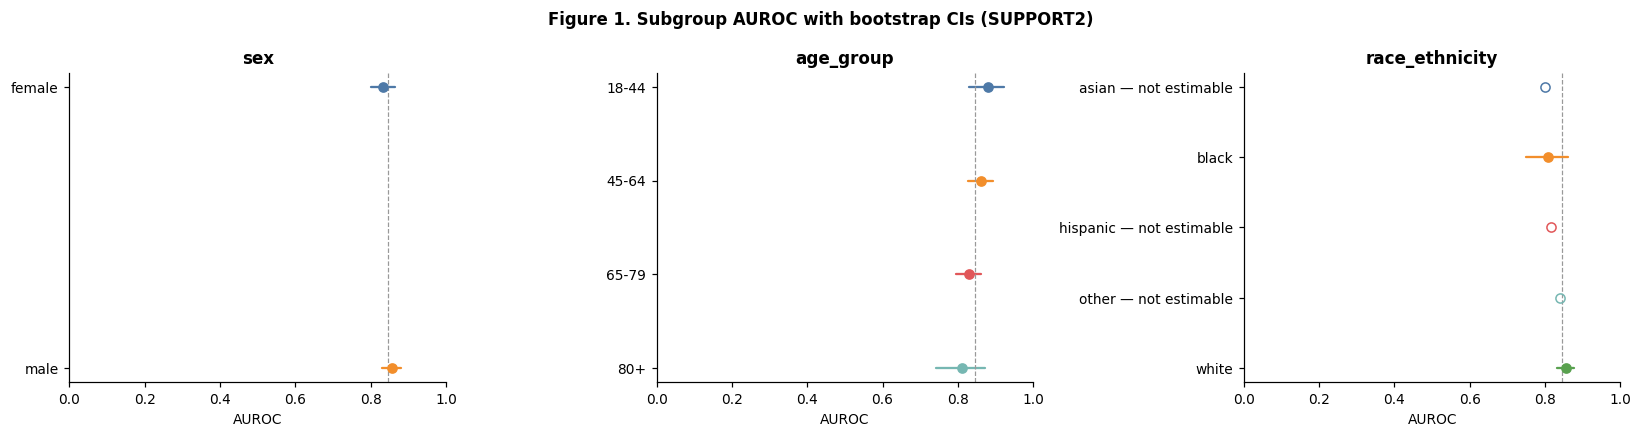

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, axis in zip(axes, attrs):
    subgroup_forest_plot(disc, attribute=axis, metric="auroc", ax=ax, title=axis)
fig.suptitle("Figure 1. Subgroup AUROC with bootstrap CIs (SUPPORT2)", fontweight="bold")
fig.tight_layout()
save(fig, "figure1_discrimination")
plt.show()

### ROC curves

Curves that cross mean no subgroup dominates at every operating point, and a
single AUROC comparison would hide it.

  wrote figureS_roc.png / .pdf


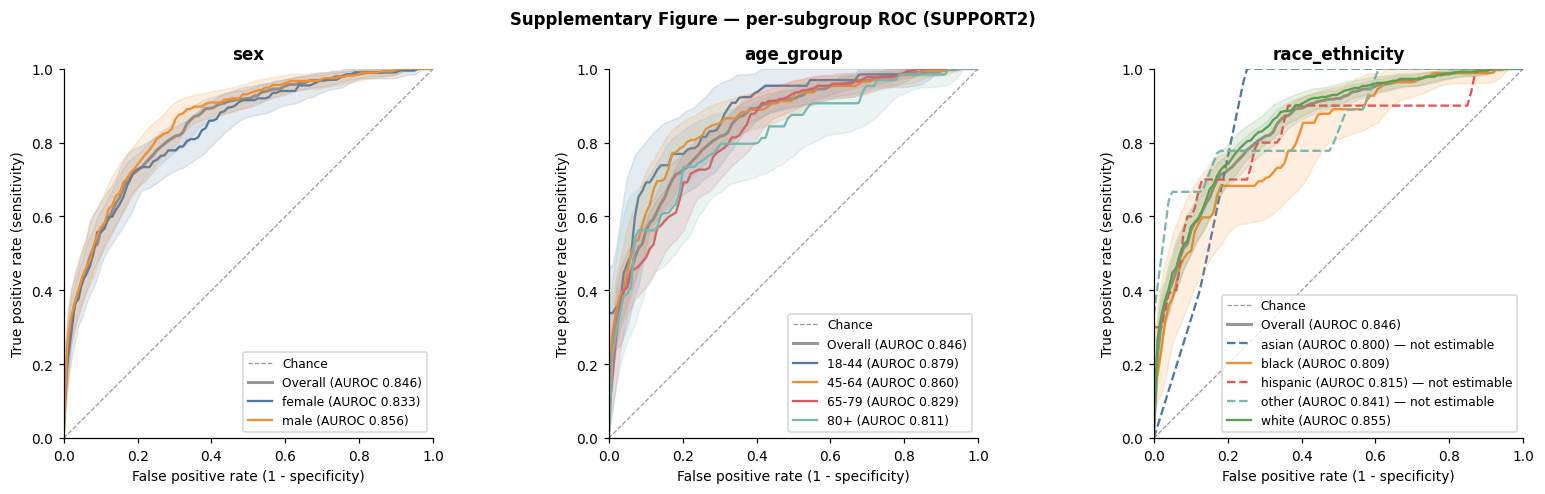

In [10]:
roc = audit.roc_curves()
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, axis in zip(axes, attrs):
    roc_plot(roc, attribute=axis, discrimination=disc, ax=ax, title=axis)
fig.suptitle("Supplementary Figure — per-subgroup ROC (SUPPORT2)", fontweight="bold")
fig.tight_layout()
save(fig, "figureS_roc")
plt.show()

### The sex-marginal paired comparison

*Paper: the abstract's "similar sex-marginal discrimination in women and men".*

A paired bootstrap on the **same** replicates, so the difference is not the
difference of two independently-drawn intervals. Report the interval, not
just the p-value.

In [11]:
sex_diff = bootstrap_metric_difference(
    y, p, attrs["sex"], metric="auc", n_boot=B, random_state=SEED, paired=True
)
print(f"observed AUROC by sex : {sex_diff.metric_observed}")
print(f"Δ AUROC               : {sex_diff.delta:+.4f}  ({sex_diff.ci_low:+.4f} to {sex_diff.ci_high:+.4f})")
print(f"p                     : {sex_diff.p_value:.3f}")
print(f"non-estimable replicates: {sex_diff.proportion_nonestimable:.1%}")

observed AUROC by sex : {'female': 0.8332478720131269, 'male': 0.8561416682310244}
Δ AUROC               : -0.0229  (-0.0638 to +0.0175)
p                     : 0.274
non-estimable replicates: 0.0%


## 6. Calibration

*Paper elements: **Table 3** and **Figure 2**.*

Three complementary views, none sufficient alone: the curve (where it fails),
the intercept and slope (how it fails), and the aggregate scores (how much).

In [12]:
cal = audit.calibration()
cal_cols = ["attribute", "subgroup", "n", "n_events",
            "calibration_intercept", "intercept_ci_low", "intercept_ci_high",
            "calibration_slope", "slope_ci_low", "slope_ci_high",
            "brier", "ece", "ici", "not_estimable_final"]
cal_within = cal[cal.subgroup != "GAP"][[c for c in cal_cols if c in cal.columns]].round(4)
emit(cal_within, "table3_calibration", "Table 3 — within-subgroup calibration")
cal_within

  wrote table3_calibration.csv / .md  (14 rows)


,attribute,subgroup,n,n_events,calibration_intercept,intercept_ci_low,intercept_ci_high,calibration_slope,slope_ci_low,slope_ci_high,brier,ece,ici,not_estimable_final
0,sex,Overall,1821.0,472.0,0.0824,-0.0478,0.2053,1.0336,0.9310,1.1457,0.1293,0.0191,0.0137,False
1,sex,female,787.0,199.0,-0.0299,-0.2241,0.1569,1.0078,0.8718,1.1691,0.1309,0.0228,0.0095,False
2,sex,male,1034.0,273.0,0.1711,-0.0021,0.3382,1.0625,0.9249,1.2242,0.1281,0.0344,0.0265,False
5,age_group,Overall,1821.0,472.0,0.0824,-0.0478,0.2053,1.0336,0.9310,1.1457,0.1293,0.0191,0.0137,False
6,age_group,18-44,257.0,65.0,-0.0252,-0.3804,0.2950,1.1738,NaN,NaN,0.1124,0.0333,0.0192,True
7,age_group,45-64,684.0,171.0,0.2674,0.0562,0.4627,1.1133,0.9408,1.3345,0.1212,0.0380,0.0311,False
8,age_group,65-79,677.0,172.0,-0.0491,-0.2697,0.1594,0.9625,0.8206,1.1295,0.1366,0.0357,0.0258,False
9,age_group,80+,203.0,64.0,0.0783,-0.2815,0.4005,0.9780,NaN,NaN,0.1537,0.0387,0.0246,True
12,race_ethnicity,Overall,1821.0,472.0,0.0824,-0.0478,0.2053,1.0336,0.9310,1.1457,0.1293,0.0191,0.0137,False
13,race_ethnicity,asian,13.0,5.0,0.6746,NaN,NaN,0.9490,NaN,NaN,0.2006,0.3488,0.1884,True


α is calibration-in-the-large, fitted with the slope pinned at 1. It is
**prevalence dependent**, so it is only interpretable against a stated
population — here, the test partition at 25.9% mortality.

β is the free fit. β < 1 means predictions are spread too wide; β > 1 that
they are too compressed. The intercept of the free fit is a different quantity
from α and must never be quoted as calibration-in-the-large.

In [13]:
cal_gaps = cal[cal.subgroup == "GAP"][
    [c for c in ["attribute", "gap_metric", "gap_value", "gap_ci_low", "gap_ci_high", "not_estimable_final"] if c in cal.columns]
].round(4)
emit(cal_gaps, "table3_calibration_gaps", "Table 3 — calibration gap statistics")
cal_gaps

  wrote table3_calibration_gaps.csv / .md  (6 rows)


,attribute,gap_metric,gap_value,gap_ci_low,gap_ci_high,not_estimable_final
3,sex,max_intercept_gap,0.2009,0.0120,0.4616,False
4,sex,max_slope_gap,0.0547,0.0036,0.2709,False
10,age_group,max_intercept_gap,0.3165,0.1663,0.7463,False
11,age_group,max_slope_gap,0.2112,NaN,NaN,True
18,race_ethnicity,max_intercept_gap,1.1673,NaN,NaN,True
19,race_ethnicity,max_slope_gap,0.2070,NaN,NaN,True


### Figure 2 — calibration curves

LOESS-smoothed with bootstrap bands, each clipped to its own subgroup's
predicted range so a curve is never drawn where that subgroup has no data.

  wrote figure2_calibration.png / .pdf


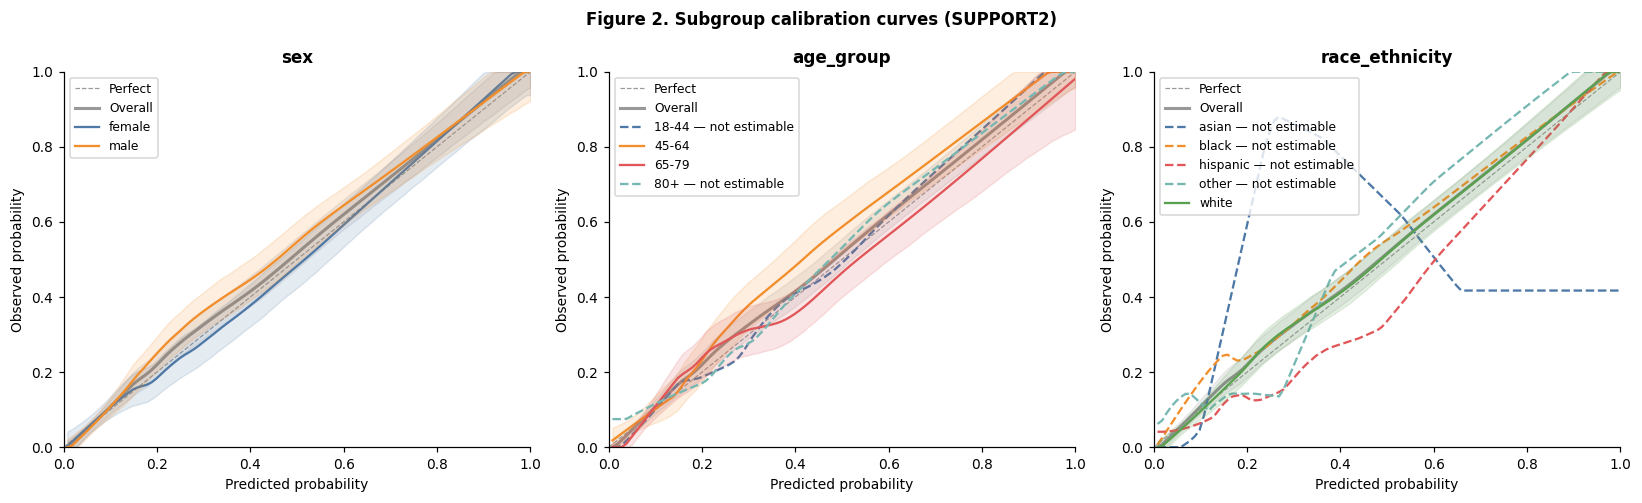

In [14]:
curves = audit.calibration_curves()
fig, axes = plt.subplots(1, 3, figsize=(15, 4.6))
for ax, axis in zip(axes, attrs):
    reliability_plot(curves, attribute=axis, calibration=cal, ax=ax, title=axis)
fig.suptitle("Figure 2. Subgroup calibration curves (SUPPORT2)", fontweight="bold")
fig.tight_layout()
save(fig, "figure2_calibration")
plt.show()

### Hosmer–Lemeshow

*Paper element: the supplementary H–L table.*

`df_mode="validation"` (df = g, not g − 2) because the predictions are out of
fold and estimate nothing on this partition. Using g − 2 here roughly doubles
the false miscalibration rate.

The statistic scales with *n*, so these values do **not** rank subgroups. And
a large p-value is not evidence of calibration — in a small subgroup it is the
expected result whether the model is calibrated or not.

In [15]:
hl = audit.hosmer_lemeshow()
hl_tbl = hl[hl.subgroup != "GAP"][
    ["attribute", "subgroup", "n", "n_events", "hl_statistic", "hl_df", "hl_p_value",
     "n_bins_used", "bins_reduced", "decile_slope", "decile_intercept"]
].round(4)
emit(hl_tbl, "tableS_hosmer_lemeshow", "Supplementary Table — Hosmer–Lemeshow by subgroup (df = g)")
hl_tbl

  wrote tableS_hosmer_lemeshow.csv / .md  (14 rows)


,attribute,subgroup,n,n_events,hl_statistic,hl_df,hl_p_value,n_bins_used,bins_reduced,decile_slope,decile_intercept
0,sex,Overall,1821.0,472.0,6.9845,10.0,0.7269,10.0,False,1.0352,0.0019
1,sex,female,787.0,199.0,4.8894,10.0,0.8984,10.0,False,0.9998,-0.0039
2,sex,male,1034.0,273.0,11.6099,10.0,0.3120,10.0,False,1.0740,0.0039
4,age_group,Overall,1821.0,472.0,6.9845,10.0,0.7269,10.0,False,1.0352,0.0019
5,age_group,18-44,257.0,65.0,3.4559,10.0,0.9686,10.0,False,1.0605,-0.0184
6,age_group,45-64,684.0,171.0,9.8624,10.0,0.4526,10.0,False,1.1139,0.0076
7,age_group,65-79,677.0,172.0,9.4136,10.0,0.4934,10.0,False,0.9278,0.0122
8,age_group,80+,203.0,64.0,2.5806,10.0,0.9896,10.0,False,1.0306,0.0025
10,race_ethnicity,Overall,1821.0,472.0,6.9845,10.0,0.7269,10.0,False,1.0352,0.0019
11,race_ethnicity,asian,13.0,5.0,12.5908,10.0,0.2475,10.0,False,0.6499,0.2768


In [16]:
hl_deciles = audit.hosmer_lemeshow(detail=True).round(4)
emit(hl_deciles, "tableS_hosmer_lemeshow_deciles", "Supplementary Table — H–L per-decile observed vs expected")
hl_deciles.head(12)

  wrote tableS_hosmer_lemeshow_deciles.csv / .md  (140 rows)


,attribute,subgroup,decile,n,observed,expected,observed_rate,expected_rate,difference
0,sex,Overall,1,183.0,4.0,4.5403,0.0219,0.0248,-0.5403
1,sex,Overall,2,182.0,6.0,7.7316,0.0330,0.0425,-1.7316
2,sex,Overall,3,182.0,11.0,10.9412,0.0604,0.0601,0.0588
3,sex,Overall,4,182.0,17.0,15.4289,0.0934,0.0848,1.5711
4,sex,Overall,5,182.0,20.0,22.8061,0.1099,0.1253,-2.8061
5,sex,Overall,6,182.0,42.0,33.2566,0.2308,0.1827,8.7434
6,sex,Overall,7,182.0,50.0,47.4057,0.2747,0.2605,2.5943
7,sex,Overall,8,182.0,76.0,68.0872,0.4176,0.3741,7.9128
8,sex,Overall,9,182.0,94.0,96.6037,0.5165,0.5308,-2.6037
9,sex,Overall,10,182.0,152.0,145.8133,0.8352,0.8012,6.1867


## 7. Clinical utility

*Paper elements: the decision-curve results and the supplementary DCA
sensitivity table.*

Net benefit over t ∈ [0.02, 0.40], with the treat-all reference computed from
**each subgroup's own prevalence** — so every subgroup is measured against the
no-model strategy as it would actually perform in that subgroup.

  wrote table_decision_curve.csv / .md  (280 rows)


  wrote figure3_decision_curves.png / .pdf


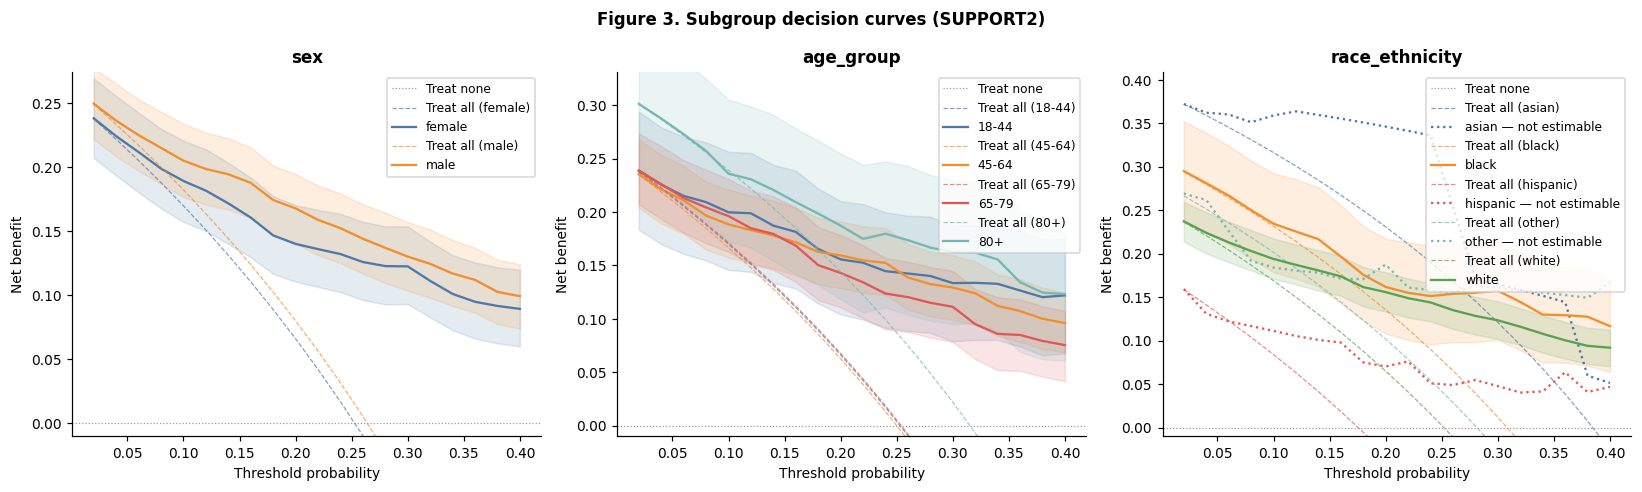

In [17]:
dc = audit.decision_curve(zero_crossing=True)
dc_cols = ["attribute", "subgroup", "threshold", "net_benefit", "net_benefit_ci_low",
           "net_benefit_ci_high", "standardized_net_benefit", "treat_all_nb", "treat_none_nb",
           "zero_crossing", "not_estimable_final"]
dc_out = dc[dc.subgroup != "GAP"][[c for c in dc_cols if c in dc.columns]].round(5)
emit(dc_out, "table_decision_curve", "Decision curve — net benefit by subgroup and threshold")

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, axis in zip(axes, attrs):
    decision_curve_plot(dc, attribute=axis, ax=ax, title=axis)
fig.suptitle("Figure 3. Subgroup decision curves (SUPPORT2)", fontweight="bold")
fig.tight_layout()
save(fig, "figure3_decision_curves")
plt.show()

### DCA sensitivity across the plausible threshold band

*Paper element: the supplementary DCA sensitivity table.*

A single threshold is a modelling choice, so net benefit is reported across a
band rather than at one point. A utility finding is one whose sign holds
across the band you could plausibly operate in.

In [18]:
BAND = [0.20, 0.25, 0.30, 0.35, 0.40]
dc_band = audit.decision_curve(thresholds=BAND)
sens = dc_band[dc_band.subgroup != "GAP"].pivot_table(
    index=["attribute", "subgroup"], columns="threshold", values="net_benefit"
).round(5).reset_index()
sens.columns = [str(c) for c in sens.columns]
emit(sens, "tableS_dca_sensitivity", "Supplementary Table — net benefit across the threshold band")
sens

  wrote tableS_dca_sensitivity.csv / .md  (14 rows)


,attribute,subgroup,0.2,0.25,0.3,0.35,0.4
0,age_group,18-44,0.15564,0.13748,0.13341,0.12870,0.12192
1,age_group,45-64,0.15936,0.14279,0.12928,0.11179,0.09600
2,age_group,65-79,0.14291,0.12112,0.11120,0.08533,0.07533
3,age_group,80+,0.18719,0.17734,0.16256,0.14248,0.12315
4,age_group,Overall,0.15582,0.13784,0.12685,0.10776,0.09500
5,race_ethnicity,Overall,0.15582,0.13784,0.12685,0.10776,0.09500
6,race_ethnicity,asian,0.34615,0.25641,0.16484,0.14793,0.05128
7,race_ethnicity,black,0.16165,0.14912,0.15736,0.12753,0.11654
8,race_ethnicity,hispanic,0.07018,0.04678,0.04762,0.06613,0.04678
9,race_ethnicity,other,0.18750,0.15625,0.16071,0.15385,0.16667


### Clinical consequences as natural frequencies

*Paper element: **Figure 3**, "clinical consequences".*

Net benefit is a rate on an unfamiliar scale. Multiplying by 1,000 turns it
into the sentence a clinician can actually check: *"per 1,000 patients, acting
on this model instead of treating no one is worth this many extra true
positives, at no additional cost in false positives."*

  wrote table_clinical_consequences.csv / .md  (14 rows)


  wrote figure4_clinical_consequences.png / .pdf


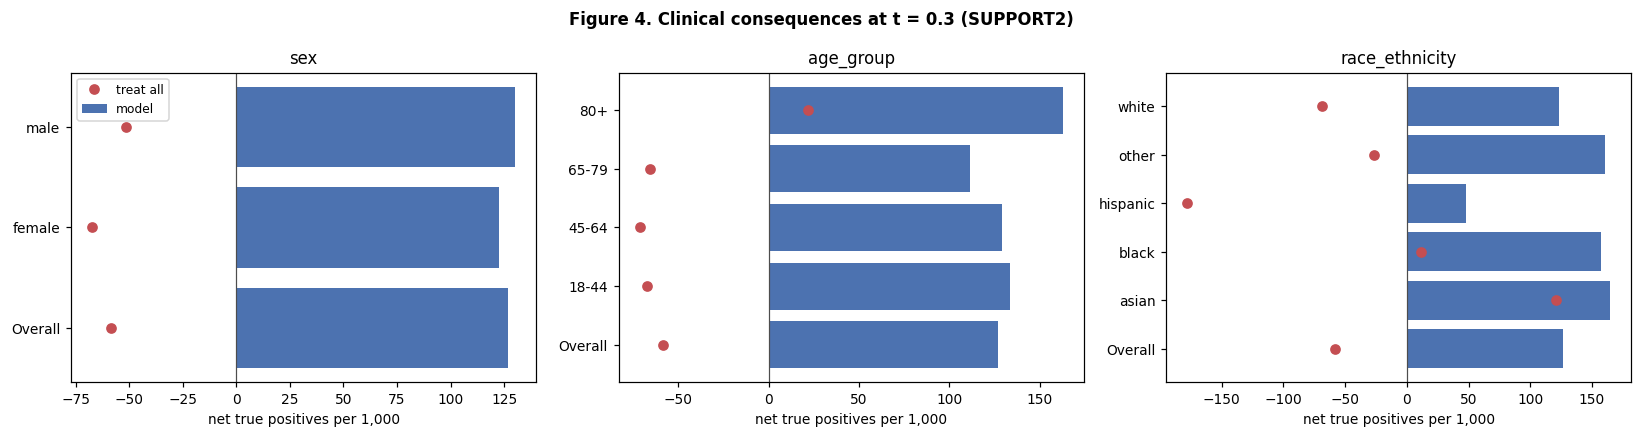

In [19]:
at_t = dc[(dc.threshold.sub(THRESHOLD).abs() < 1e-9) & (dc.subgroup != "GAP")].copy()
at_t["nb_per_1000"] = (at_t["net_benefit"] * 1000).round(1)
at_t["treat_all_per_1000"] = (at_t["treat_all_nb"] * 1000).round(1)
cons = at_t[["attribute", "subgroup", "nb_per_1000", "treat_all_per_1000", "standardized_net_benefit"]].round(4)
emit(cons, "table_clinical_consequences", f"Clinical consequences per 1,000 patients at t = {THRESHOLD}")

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, axis in zip(axes, attrs):
    sub = cons[cons.attribute == axis]
    ypos = np.arange(len(sub))
    ax.barh(ypos, sub["nb_per_1000"], color="#4C72B0", label="model")
    ax.plot(sub["treat_all_per_1000"], ypos, "o", color="#C44E52", label="treat all")
    ax.set_yticks(ypos, sub["subgroup"])
    ax.axvline(0, color="0.3", lw=0.8)
    ax.set_xlabel("net true positives per 1,000")
    ax.set_title(axis)
axes[0].legend(fontsize=8)
fig.suptitle(f"Figure 4. Clinical consequences at t = {THRESHOLD} (SUPPORT2)", fontweight="bold")
fig.tight_layout()
save(fig, "figure4_clinical_consequences")
plt.show()

## 8. Estimability — what may be reported at all

*Paper section: Supplementary Methods, "Uncertainty quantification and
multiple comparisons".*

This is the package's most consequential rule, and it answers one question in
a single table: which estimates this cohort supports an interval for. A
cell-metric is reportable when it clears **both**:

1. **the event floor** for that metric — the conservative union is imported,
   never restated inline, so a change propagates everywhere at once;
2. **the replicate rule** — at most 10% of bootstrap replicates non-estimable.

A gap inherits the verdict of both constituent subgroups. Suppression
withholds the **interval and keeps the point estimate**: the value is real,
and what the data cannot support is an interval around it.

In [20]:
print("Pre-registered event floors (imported from isitfair.estimability):")
for metric, floor in sorted(DEFAULT_EVENT_FLOORS.items()):
    print(f"  {metric:>24} : {floor}")

est = audit.estimability()
est_out = est[["attribute", "subgroup", "metric", "n", "n_events", "event_floor",
               "below_floor", "proportion_nonestimable", "rule", "not_estimable_final"]].round(4)
emit(est_out, "table_estimability", "Estimability verdict for every audited cell-metric")

n_bad = int(est.not_estimable_final.sum())
print(f"\n{n_bad} of {len(est)} cell-metrics are not reportable ({n_bad / len(est):.0%}).")
print("Driven by the sparse race/ethnicity strata:")
print(est[est.not_estimable_final].groupby("subgroup").size().sort_values(ascending=False).to_string())

Pre-registered event floors (imported from isitfair.estimability):
                     auroc : 25
     calibration_intercept : 25
         calibration_slope : 100
               net_benefit : 50
  wrote table_estimability.csv / .md  (178 rows)

41 of 178 cell-metrics are not reportable (23%).
Driven by the sparse race/ethnicity strata:
subgroup
other       10
hispanic    10
asian       10
GAP          8
18-44        1
80+          1
black        1


## 9. Mitigation — the recalibration ladder

*Paper elements: **Table 4** and **Figure 5**.*

Three rungs, climbed in order, never jumped:

| Rung | What it does | What it costs |
|---|---|---|
| 0 · none | the model as it stands | — |
| 1 · common | one cohort-wide recalibration | uses no group membership |
| 2 · group-specific | a separate map per subgroup | needs enough events *per group* |

All rungs are cross-fitted, because a recalibration map is itself a fitted
model: evaluating it on the data that fitted it is the same in-sample optimism
the audit exists to avoid.

In [21]:
ladder = audit.recalibration_ladder(
    by="race_ethnicity", method="isotonic", cv=5, random_state=SEED
)
ladder_out = ladder.round(4)
emit(ladder_out, "table4_recalibration_ladder", "Table 4 — recalibration ladder on the race/ethnicity axis")
ladder_out

  wrote table4_recalibration_ladder.csv / .md  (21 rows)


,rung,attribute,subgroup,n,n_events,calibration_intercept,intercept_ci_low,intercept_ci_high,calibration_slope,slope_ci_low,...,brier_ci_low,brier_ci_high,ece,ici,net_benefit,gap_metric,gap_value,event_floor,below_floor,not_estimable_final
0,none,race_ethnicity,Overall,1821.0,472.0,0.0824,-0.0502,0.2083,1.0336,0.9324,...,0.1193,0.1393,0.0191,0.0137,0.1269,NaN,NaN,25.0,False,False
1,none,race_ethnicity,asian,13.0,5.0,0.6746,NaN,NaN,0.9490,NaN,...,NaN,NaN,0.3488,0.1884,0.1648,NaN,NaN,25.0,True,True
2,none,race_ethnicity,black,266.0,82.0,0.3364,-0.0128,0.6611,0.8708,NaN,...,0.1285,0.1870,0.0552,0.0432,0.1574,NaN,NaN,25.0,False,True
3,none,race_ethnicity,hispanic,57.0,10.0,-0.4927,NaN,NaN,0.9476,NaN,...,NaN,NaN,0.0981,0.0571,0.0476,NaN,NaN,25.0,True,True
4,none,race_ethnicity,other,32.0,9.0,0.4310,NaN,NaN,0.9413,NaN,...,NaN,NaN,0.1236,0.0694,0.1607,NaN,NaN,25.0,True,True
5,none,race_ethnicity,white,1453.0,366.0,0.0390,-0.1055,0.1739,1.0778,0.9656,...,0.1134,0.1351,0.0238,0.0141,0.1233,NaN,NaN,25.0,False,False
6,none,race_ethnicity,GAP,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,max_intercept_gap,1.1673,NaN,NaN,NaN
7,common,race_ethnicity,Overall,1821.0,472.0,0.0001,-0.1384,0.1324,0.7671,0.5923,...,0.1216,0.1421,0.0188,0.0088,0.1251,NaN,NaN,25.0,False,False
8,common,race_ethnicity,asian,13.0,5.0,0.7072,NaN,NaN,0.7245,NaN,...,NaN,NaN,0.3645,0.2430,0.1648,NaN,NaN,25.0,True,True
9,common,race_ethnicity,black,266.0,82.0,0.2438,-0.1180,0.5855,0.5109,NaN,...,0.1304,0.1886,0.0646,0.0418,0.1525,NaN,NaN,25.0,False,True


  wrote figure5_recalibration_ladder.png / .pdf


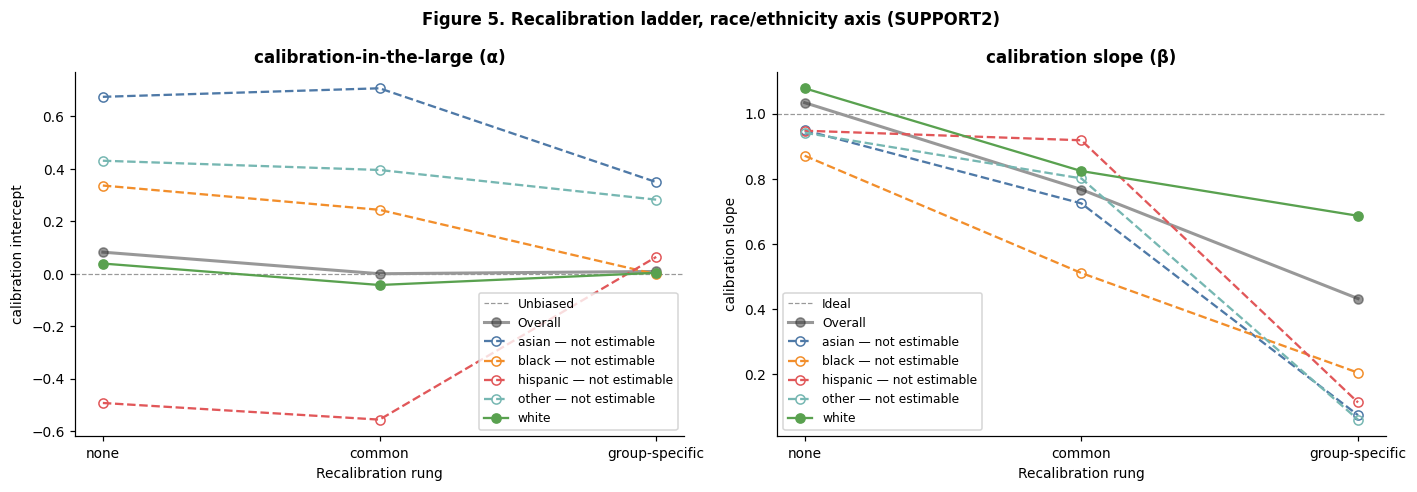

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
recalibration_ladder_plot(ladder, metric="calibration_intercept", ax=axes[0], title="calibration-in-the-large (α)")
recalibration_ladder_plot(ladder, metric="calibration_slope", ax=axes[1], title="calibration slope (β)")
fig.suptitle("Figure 5. Recalibration ladder, race/ethnicity axis (SUPPORT2)", fontweight="bold")
fig.tight_layout()
save(fig, "figure5_recalibration_ladder")
plt.show()

### When the ladder tells you to stop

The paper's finding on its own cohort was that group-specific recalibration
overfits sparse strata and should be deferred. **That reproduces here, on
entirely different data**: below, group-specific isotonic recalibration
collapses the calibration slope in the small race/ethnicity strata, because a
monotone step function fitted on a handful of events is a near-degenerate map.

This is the levelling-down check (Pfohl et al. 2021) doing its job. Read the
slope column, not the intercept.

In [23]:
audit_pre = FairnessAudit(
    y_true=y, y_proba=p, sensitive_features=attrs,
    threshold=THRESHOLD, n_bootstrap=B, random_state=SEED,
)
mitigated = audit_pre.mitigate(
    method=GroupRecalibration(method="isotonic"),
    calibration_data=(cohort.y_calib, cohort.p_calib, cohort.attrs_calib),
)
keep = ["subgroup", "n", "n_events", "calibration_intercept", "calibration_slope", "brier", "ece"]
before = audit_pre.calibration()
after = mitigated["race_ethnicity"].calibration()
comparison = (
    before[before.attribute == "race_ethnicity"][keep]
    .merge(
        after[after.attribute == "race_ethnicity"][keep],
        on=["subgroup", "n", "n_events"], suffixes=("_before", "_after"),
    )
    .round(4)
)
emit(comparison, "table4_mitigation_before_after", "Table 4 — group-specific isotonic recalibration, before vs after")
comparison

  wrote table4_mitigation_before_after.csv / .md  (10 rows)


,subgroup,n,n_events,calibration_intercept_before,calibration_slope_before,brier_before,ece_before,calibration_intercept_after,calibration_slope_after,brier_after,ece_after
0,Overall,1821.0,472.0,0.0824,1.0336,0.1293,0.0191,0.0579,0.6286,0.1313,0.0202
1,asian,13.0,5.0,0.6746,0.9490,0.2006,0.3488,0.9985,0.6474,0.2354,0.2295
2,black,266.0,82.0,0.3364,0.8708,0.1573,0.0552,0.2465,0.4433,0.1588,0.0502
3,hispanic,57.0,10.0,-0.4927,0.9476,0.1060,0.0981,-0.9797,0.1135,0.1225,0.1485
4,other,32.0,9.0,0.4310,0.9413,0.1257,0.1236,-0.7319,0.0792,0.1475,0.1623
5,white,1453.0,366.0,0.0390,1.0778,0.1245,0.0238,0.0515,0.9057,0.1254,0.0272
6,GAP,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,GAP,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,GAP,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,GAP,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### The Wasserstein comparator

*Paper element: the supplementary Wasserstein-barycenter comparison.*

Score-distribution parity is included as a **comparator, not a
recommendation**. It aligns the subgroup score distributions exactly and
preserves within-subgroup AUROC by construction — and calibration should be
expected to get *worse*, because calibration and demographic parity cannot
both hold when prevalence differs across groups (Pleiss et al. 2017).

In [24]:
wass = audit_pre.mitigate(
    method=WassersteinPostprocessing(constraint="demographic_parity"),
    calibration_data=(cohort.y_calib, cohort.p_calib, cohort.attrs_calib),
)
w_cal = wass["race_ethnicity"].calibration()
w_out = w_cal[w_cal.attribute == "race_ethnicity"][keep].round(4)
emit(w_out, "tableS_mitigation_wasserstein", "Supplementary Table — Wasserstein demographic-parity comparator")
w_out

  wrote tableS_mitigation_wasserstein.csv / .md  (8 rows)


,subgroup,n,n_events,calibration_intercept,calibration_slope,brier,ece
12,Overall,1821.0,472.0,0.0734,1.0294,0.1301,0.0185
13,asian,13.0,5.0,1.4163,1.5801,0.2653,0.3834
14,black,266.0,82.0,0.3225,0.8940,0.1573,0.0550
15,hispanic,57.0,10.0,-0.5326,0.8949,0.1077,0.0823
16,other,32.0,9.0,1.0388,1.3081,0.1453,0.1413
17,white,1453.0,366.0,0.0085,1.0783,0.1244,0.0216
18,GAP,NaN,NaN,NaN,NaN,NaN,NaN
19,GAP,NaN,NaN,NaN,NaN,NaN,NaN


## 10. Intersectional and secondary interaction analyses

*Paper section: Results — "Intersectional and secondary interaction
analyses".*

### 10a. Sex × race/ethnicity cells

Ten cells across a wide range of sizes — the case empirical-Bayes shrinkage
exists for. Cells below the event threshold are shrunk toward the first
constituent's marginal rates; only **rate** metrics are shrunk, AUROC and
AUPRC keep their own values, and a shrunken cell carries NaN intervals so the
borrowing stays visible.

In [25]:
audit_inter = FairnessAudit(
    y_true=y, y_proba=p,
    sensitive_features={**attrs, ("sex", "race_ethnicity"): None},
    threshold=THRESHOLD, n_bootstrap=B, random_state=SEED,
)
cells = audit_inter.cell_diagnostics().round(4)
emit(cells, "tableS_intersectional_cells", "Supplementary Table — sex × race/ethnicity cell diagnostics")
cells

  wrote tableS_intersectional_cells.csv / .md  (10 rows)


,attribute,subgroup,n,n_events,shrunk,marginal_rate,cell_rate,shrinkage_factor
0,sex × race_ethnicity,female / asian,2,2,True,0.2529,1.0000,0.9880
1,sex × race_ethnicity,female / black,127,40,True,0.2529,0.3150,0.5654
2,sex × race_ethnicity,female / hispanic,24,3,True,0.2529,0.1250,0.8732
3,sex × race_ethnicity,female / other,14,6,True,0.2529,0.4286,0.9219
4,sex × race_ethnicity,female / white,620,148,False,0.2529,0.2387,0.2104
5,sex × race_ethnicity,male / asian,11,3,True,0.2640,0.2727,0.9376
6,sex × race_ethnicity,male / black,139,42,True,0.2640,0.3022,0.5431
7,sex × race_ethnicity,male / hispanic,33,7,True,0.2640,0.2121,0.8335
8,sex × race_ethnicity,male / other,18,3,True,0.2640,0.1667,0.9017
9,sex × race_ethnicity,male / white,833,218,False,0.2640,0.2617,0.1655


### 10b. Feature-by-sex effect-size scan

*Paper elements: **Supplementary Table S1** and **Figure 5A** (the volcano).
Supplementary Methods FDR family (d).*

Which patient characteristics actually differ between the sexes in this
cohort? Cohen's d for continuous variables, Cohen's h for binary ones, with
BH-FDR across the whole scan, since a 15-variable sweep at α = 0.05 expects a
false positive on its own.

In [26]:
from scipy import stats

fem = frame["sex"] == "female"
scan = []
for var in T1_CONTINUOUS:
    a, b = frame.loc[fem, var].dropna(), frame.loc[~fem, var].dropna()
    scan.append({"variable": var, "kind": "continuous", "effect_size": cohens_d(a, b),
                 "p_value": stats.mannwhitneyu(a, b, alternative="two-sided").pvalue})
for var in T1_BINARY:
    a, b = frame.loc[fem, var].dropna(), frame.loc[~fem, var].dropna()
    table = np.array([[a.sum(), len(a) - a.sum()], [b.sum(), len(b) - b.sum()]])
    scan.append({"variable": var, "kind": "binary", "effect_size": cohens_h(a.mean(), b.mean()),
                 "p_value": stats.chi2_contingency(table).pvalue})

scan_df = pd.DataFrame(scan)
scan_df["q_fdr"] = fdr_correct(scan_df["p_value"])
scan_df = scan_df.sort_values("q_fdr").round(5)
emit(scan_df, "tableS1_feature_by_sex", "Supplementary Table S1 — feature-by-sex effect sizes with BH-FDR")
scan_df

  wrote tableS1_feature_by_sex.csv / .md  (13 rows)


,variable,kind,effect_size,p_value,q_fdr
6,crea,continuous,-0.10011,0.00025,0.00327
11,diabetes,binary,0.13247,0.00590,0.03832
10,scoma,continuous,0.05230,0.01581,0.06851
1,num.co,continuous,-0.07932,0.09402,0.30557
0,age,continuous,0.06318,0.14301,0.37184
8,sps,continuous,0.03950,0.19727,0.42741
9,aps,continuous,0.04201,0.24638,0.45756
2,meanbp,continuous,0.04911,0.49571,0.60001
12,dementia,binary,0.04685,0.38483,0.60001
3,hrt,continuous,0.00865,0.50770,0.60001


  wrote figure6a_volcano_sex.png / .pdf


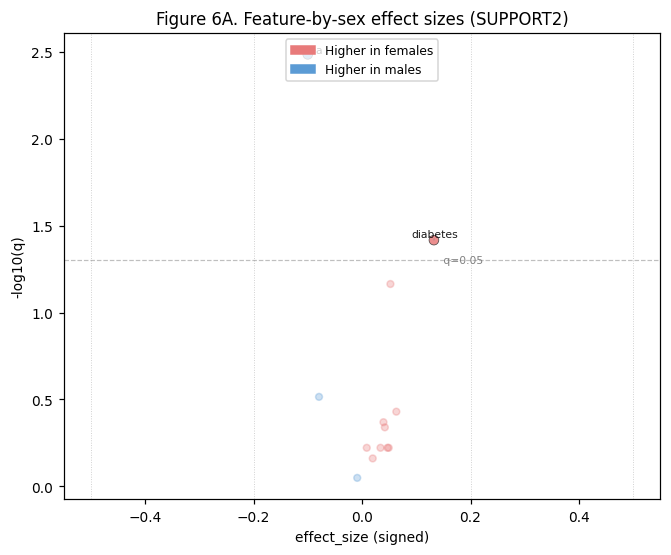

In [27]:
fig, ax = plt.subplots(figsize=(7, 5.5))
volcano_plot(
    scan_df, positive_label="Higher in females", negative_label="Higher in males",
    label_min_effect=0.05, title="Figure 6A. Feature-by-sex effect sizes (SUPPORT2)", ax=ax,
)
save(fig, "figure6a_volcano_sex")
plt.show()

### 10c. Comorbidity × sex interaction screen

*Paper elements: **Supplementary Table S5** and **Figure 5B** (the forest).
Supplementary Methods FDR family (b).*

The question is a narrow one, and worth stating precisely: not "does mortality
differ by sex within this comorbidity", which largely restates the
comorbidity's own rate, but "does the *effect* of the comorbidity differ by
sex". That is a likelihood-ratio test on nested logistic models, and it needs
`delta_r2` reported next to the p-value, because with n in the thousands a
vanishing interaction is still detectable.

In [28]:
COMORBIDITIES = ["diabetes", "dementia"]
frame_ix = frame.copy()
frame_ix["cancer"] = (frame_ix["ca"] != "no").astype(int)
frame_ix["multi_comorbid"] = (frame_ix["num.co"] >= 2).astype(int)
frame_ix["severe_coma"] = (frame_ix["scoma"] > 0).astype(int)
frame_ix["age_years"] = frame_ix["age"]
frame_ix["severity"] = frame_ix["aps"]
COMORBIDITIES += ["cancer", "multi_comorbid", "severe_coma"]

interactions = []
for cond in COMORBIDITIES:
    res = interaction_test(
        frame_ix, outcome="y", sensitive="sex", covariate=cond,
        adjust_for=("age_years", "severity"),
    )
    row = {"comorbidity": cond, "lrt_stat": res.statistic, "df": res.df,
           "p_interaction": res.p_value, "delta_r2": res.delta_r2, "n": res.n}
    for sex_level in ("female", "male"):
        m = frame_ix["sex"] == sex_level
        orr = odds_ratio_2x2(frame_ix.loc[m, cond], frame_ix.loc[m, "y"])
        row |= {
            f"or_{sex_level}": orr.odds_ratio,
            f"or_{sex_level}_low": orr.ci_low,
            f"or_{sex_level}_high": orr.ci_high,
            f"n_exposed_{sex_level}": orr.n_exposed,
        }
    interactions.append(row)

ix_df = pd.DataFrame(interactions)
ix_df["q_interaction"] = fdr_correct(ix_df["p_interaction"])
ix_df = ix_df.round(5)
emit(ix_df, "tableS5_comorbidity_sex_interaction", "Supplementary Table S5 — comorbidity × sex interaction (LRT + BH-FDR)")
ix_df

  wrote tableS5_comorbidity_sex_interaction.csv / .md  (5 rows)


,comorbidity,lrt_stat,df,p_interaction,delta_r2,n,or_female,or_female_low,or_female_high,n_exposed_female,or_male,or_male_low,or_male_high,n_exposed_male,q_interaction
0,diabetes,1.17450,1,0.27848,0.00064,1821,0.88479,0.59229,1.32175,166,1.13323,0.78238,1.64141,165,0.91795
1,dementia,0.00439,1,0.94716,0.00000,1821,1.57979,0.74781,3.33740,32,1.85250,0.90858,3.77706,33,0.94716
2,cancer,0.35594,1,0.55077,0.00020,1821,0.76219,0.53350,1.08891,247,0.92280,0.69042,1.23340,370,0.91795
3,multi_comorbid,0.09864,1,0.75346,0.00005,1821,0.75562,0.54733,1.04316,401,0.77236,0.58542,1.01899,564,0.94183
4,severe_coma,0.60788,1,0.43559,0.00033,1821,4.48811,3.19071,6.31305,240,4.06179,2.99855,5.50204,256,0.91795


  wrote figure6b_forest_comorbidity_sex.png / .pdf


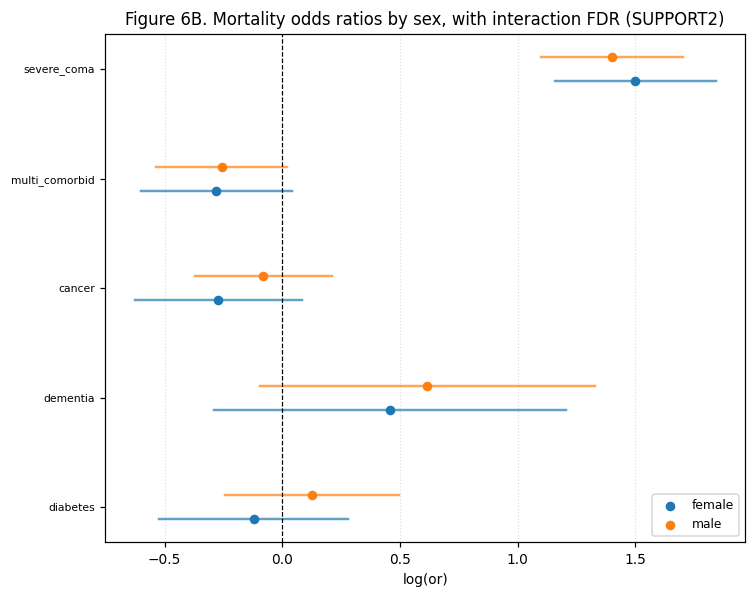

In [29]:
forest_rows = []
for _, r in ix_df.iterrows():
    for sex_level in ("female", "male"):
        forest_rows.append({
            "variable": r["comorbidity"], "sex": sex_level,
            "or": r[f"or_{sex_level}"], "low": r[f"or_{sex_level}_low"],
            "high": r[f"or_{sex_level}_high"], "q_fdr": r["q_interaction"],
        })
fig, ax = plt.subplots(figsize=(7.5, 6))
forest_plot(
    pd.DataFrame(forest_rows), estimate_col="or", ci_low_col="low", ci_high_col="high",
    group_col="sex", q_col="q_fdr", log_scale=True, null_value=1.0,
    title="Figure 6B. Mortality odds ratios by sex, with interaction FDR (SUPPORT2)", ax=ax,
)
save(fig, "figure6b_forest_comorbidity_sex")
plt.show()

## 11. Comparing audits side by side

`compare_periods` lines one axis up across several audits and returns them as a
single frame with a `delta` column — a development window against a later
deployment window, two sites, or two versions of the same model.

You construct each audit yourself and hand them over as a dict, which keeps
every modelling decision — which rows, which model, which threshold — in your
hands. Below, the test partition is split in two to show the output shape;
with real windows you would build each audit from its own period.

In [30]:
half = len(y) // 2
part_a = FairnessAudit(
    y_true=y[:half], y_proba=p[:half],
    sensitive_features={k: v[:half] for k, v in attrs.items()},
    threshold=THRESHOLD, n_bootstrap=B, random_state=SEED,
)
part_b = FairnessAudit(
    y_true=y[half:], y_proba=p[half:],
    sensitive_features={k: v[half:] for k, v in attrs.items()},
    threshold=THRESHOLD, n_bootstrap=B, random_state=SEED,
)
periods = compare_periods(
    {"Evaluation partition A": part_a, "Evaluation partition B": part_b},
    axis="calibration", attribute="sex",
).round(4)
emit(periods, "table_compare_periods", "Calibration by sex across two evaluation partitions")
periods

  wrote table_compare_periods.csv / .md  (15 rows)


,attribute,subgroup,metric,Evaluation partition A,Evaluation partition A_ci_low,Evaluation partition A_ci_high,Evaluation partition A_n_events,Evaluation partition B,Evaluation partition B_ci_low,Evaluation partition B_ci_high,Evaluation partition B_n_events,delta,periods_estimable,not_estimable
0,sex,Overall,brier,0.1241,0.1110,0.1377,226.0,0.1345,0.1206,0.1491,246.0,0.0104,2,False
1,sex,Overall,calibration_intercept,0.0113,-0.1709,0.1931,226.0,0.1521,-0.0348,0.3301,246.0,0.1407,2,False
2,sex,Overall,calibration_slope,1.0710,0.9285,1.2441,226.0,1.0002,0.8756,1.1540,246.0,-0.0708,2,False
3,sex,Overall,ece,0.0324,NaN,NaN,226.0,0.0218,NaN,NaN,246.0,-0.0106,2,False
4,sex,Overall,ici,0.0148,NaN,NaN,226.0,0.0197,NaN,NaN,246.0,0.0049,2,False
5,sex,female,brier,0.1302,0.1102,0.1507,102.0,0.1315,0.1107,0.1531,97.0,0.0012,2,False
6,sex,female,calibration_intercept,-0.0019,-0.2595,0.2595,102.0,-0.0603,-0.3597,0.2180,97.0,-0.0584,2,False
7,sex,female,calibration_slope,1.0682,0.8646,1.3376,102.0,0.9512,NaN,NaN,97.0,-0.1170,1,True
8,sex,female,ece,0.0419,NaN,NaN,102.0,0.0466,NaN,NaN,97.0,0.0046,1,True
9,sex,female,ici,0.0103,NaN,NaN,102.0,0.0243,NaN,NaN,97.0,0.0140,1,True


## 12. What this run produced

Every table and figure above is on disk. The audit report itself comes from
`examples/support2_mortality_audit.py` — see notebook 01.

In [31]:
print("results/tables/")
for f in sorted(TABLES.glob("*.csv")):
    print(f"  {f.name}")
print("\nresults/figures/")
for f in sorted(FIGURES.glob("*.png")):
    print(f"  {f.name}")

results/tables/
  table1_by_race_effect_sizes.csv
  table1_by_sex_effect_sizes.csv
  table2_discrimination.csv
  table2_discrimination_gaps.csv
  table3_calibration.csv
  table3_calibration_gaps.csv
  table4_mitigation_before_after.csv
  table4_recalibration_ladder.csv
  table_clinical_consequences.csv
  table_compare_periods.csv
  table_decision_curve.csv
  table_estimability.csv
  table_subgroup_distribution.csv
  tableS1_feature_by_sex.csv
  tableS5_comorbidity_sex_interaction.csv
  tableS_dca_sensitivity.csv
  tableS_hosmer_lemeshow.csv
  tableS_hosmer_lemeshow_deciles.csv
  tableS_intersectional_cells.csv
  tableS_mitigation_wasserstein.csv

results/figures/
  figure1_discrimination.png
  figure2_calibration.png
  figure3_decision_curves.png
  figure4_clinical_consequences.png
  figure5_recalibration_ladder.png
  figure6a_volcano_sex.png
  figure6b_forest_comorbidity_sex.png
  figureS_roc.png


## What this audit establishes

Five concrete statements about the model, each backed by a table above:

1. **Which subgroups it was measured in, and how well the data supports each
   estimate.** §8 gives that verdict per cell, so every number in the report
   arrives with its own evidence base attached.
2. **Which axis carries the finding** — discrimination, calibration or
   clinical utility. They are independent, so a model can rank well and still
   print risks worth correcting.
3. **How to read each gap**: a deployment-relevant difference, case-mix
   heterogeneity the model is right to reflect, or a contrast this cohort is
   too sparse to resolve.
4. **Which remedy the evidence supports.** §9 climbed the ladder rung by rung
   and showed where the gain stops — common recalibration moved
   calibration-in-the-large to essentially zero without using group membership
   at all.
5. **What was prespecified and what came from looking** — the threshold, the
   floors and the FDR families were all fixed in advance.

### References

- Knaus WA, et al. The SUPPORT prognostic model. *Ann Intern Med* 1995;122:191–203.
- Kramer AA, Zimmerman JE. Assessing the calibration of mortality benchmarks in critical care. *Crit Care Med* 2007;35:2052–6.
- Vickers AJ, Elkin EB. Decision curve analysis. *Med Decis Making* 2006;26:565–74.
- Pleiss G, et al. On fairness and calibration. *NeurIPS* 2017.
- Pfohl SR, et al. An empirical characterization of fair machine learning for clinical risk prediction. *J Biomed Inform* 2021;113:103621.
- Collins GS, et al. TRIPOD+AI statement. *BMJ* 2024;385:e078378.